# Gigavolt Vector Search: Chunking, Embeddings and Retrieval Benchmark

Analysis of the chunking pipeline, HNSW tuning and retrieval quality for the technical-document vector store.

**Dataset:** 25 technical PDF documents (manuals, SOPs, datasheets, change orders, incident and supplier reports).

**Pipeline:** PDF extraction → document-level overlapping chunks → E5 embeddings → persistent ChromaDB collection → HNSW tuning → semantic search and evaluation.

The notebook reads artifacts produced by the scripts in `m4-semantic-search/scripts/`. It does not regenerate embeddings or modify the database.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import os

# Point GIGAVOLT_PROCESSED_DIR at the folder written by the vector_search scripts.
DATA_DIR = Path(os.getenv("GIGAVOLT_PROCESSED_DIR", "../../data/processed")).resolve()

required_files = [
    "summary.json",
    "chunks.jsonl",
    "chroma_hnsw_tuning.csv",
    "chroma_final_benchmark.csv",
    "relevance_summary.csv",
]

missing = [name for name in required_files if not (DATA_DIR / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing expected artifacts: {missing}")

summary = json.loads((DATA_DIR / "summary.json").read_text(encoding="utf-8"))
chunks = pd.read_json(DATA_DIR / "chunks.jsonl", lines=True)
tuning = pd.read_csv(DATA_DIR / "chroma_hnsw_tuning.csv")
benchmark = pd.read_csv(DATA_DIR / "chroma_final_benchmark.csv")
source_eval = pd.read_csv(DATA_DIR / "relevance_summary.csv")

print("Artifacts directory:", DATA_DIR)
print("PDFs:", summary["pdf_count"])
print("Pages:", summary["total_pages"])
print("Pages with text:", summary["pages_with_text"])
print("Chunks:", len(chunks))
print("Embedding model:", summary["tokenizer_model"])
print("Chunk target:", summary["target_chunk_tokens"])
print("Overlap target:", summary["target_overlap_tokens"])
print("Final benchmark rows:", len(benchmark))
print("HNSW tuning configurations:", len(tuning))

Artifacts directory: data/processed
PDFs: 25
Pages: 54
Pages with text: 53
Chunks: 64
Embedding model: intfloat/e5-small-v2
Chunk target: 300
Overlap target: 50
Final benchmark rows: 32
HNSW tuning configurations: 9


## 1. Chunking validation

The chunker uses a 300-token target and approximately 50 tokens of overlap. It processes each complete PDF, so chunks can span page boundaries while retaining source page metadata.

The following checks validate the saved chunk records.

In [2]:
target = int(summary["target_chunk_tokens"])
overlap_target = int(summary["target_overlap_tokens"])

assert chunks["chunk_id"].is_unique, "Duplicate chunk IDs found."
assert chunks["chunk_text"].notna().all(), "Missing chunk text."
assert (chunks["chunk_text"].str.strip().str.len() > 0).all(), "Empty chunks found."

print("Unique chunk IDs:", chunks["chunk_id"].nunique())
print("Maximum saved chunk tokens:", chunks["token_count"].max())
print("Chunks exceeding target:", int((chunks["token_count"] > target).sum()))

overlaps = chunks["overlap_tokens_with_previous"].fillna(0).astype(int)
overlap_pairs = overlaps[overlaps > 0]

print("Adjacent pairs with overlap:", len(overlap_pairs))
print("Minimum overlap:", overlap_pairs.min() if len(overlap_pairs) else None)
print("Average overlap:", round(overlap_pairs.mean(), 2) if len(overlap_pairs) else None)
print("Pairs meeting 50-token target:", int((overlap_pairs >= overlap_target).sum()), "/", len(overlap_pairs))
print("Low-text PDF pages:", len(summary.get("low_text_pages", [])))

display(chunks[[
    "chunk_id", "source_filename", "page_start", "page_end",
    "token_count", "overlap_tokens_with_previous"
]].head(10))

Unique chunk IDs: 64
Maximum saved chunk tokens: 300
Chunks exceeding target: 0
Adjacent pairs with overlap: 39
Minimum overlap: 50
Average overlap: 54.41
Pairs meeting 50-token target: 39 / 39
Low-text PDF pages: 1


,chunk_id,source_filename,page_start,page_end,token_count,overlap_tokens_with_previous
0,f3159dbf5de4b71b-c0001,GV-ECO-2024-019 Engineering Change Order.pdf,1,1,297,0
1,f3159dbf5de4b71b-c0002,GV-ECO-2024-019 Engineering Change Order.pdf,1,2,205,51
2,64bf648ee6aedf50-c0001,GV-ECO-2024-031 Change Order - Chiller Relief ...,1,1,297,0
3,64bf648ee6aedf50-c0002,GV-ECO-2024-031 Change Order - Chiller Relief ...,1,2,217,57
4,4149265d196877f4-c0001,GV-ECO-2024-044 Change Order Re-torque.pdf,1,1,294,0
5,4149265d196877f4-c0002,GV-ECO-2024-044 Change Order Re-torque.pdf,1,2,171,50
6,6c64d5a10a3e902b-c0001,GV-ECO-2024-052 Change Order Cabinet Door Seal...,1,1,296,0
7,6c64d5a10a3e902b-c0002,GV-ECO-2024-052 Change Order Cabinet Door Seal...,1,2,225,50
8,e3084a2dbe5bf037-c0001,GV-INC-2024-088 Field Incident Investigation R...,1,1,280,0
9,e3084a2dbe5bf037-c0002,GV-INC-2024-088 Field Incident Investigation R...,1,2,288,62


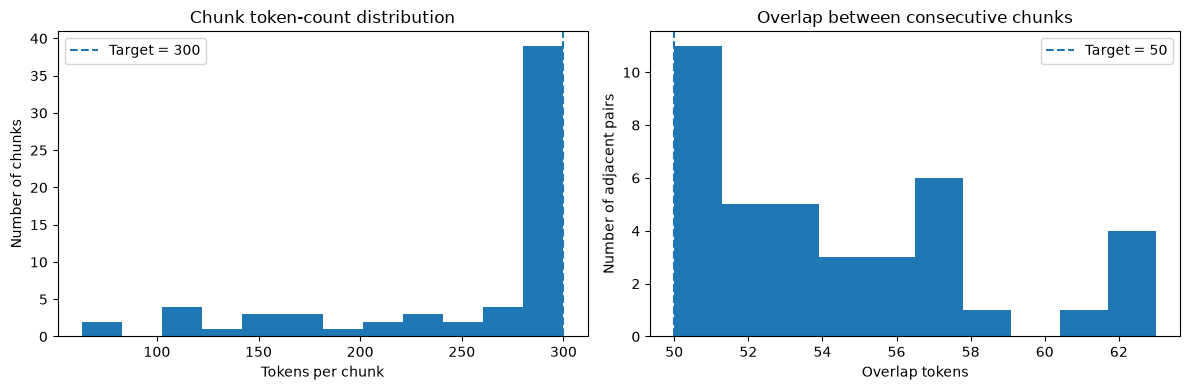

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(chunks["token_count"], bins=12)
axes[0].axvline(target, linestyle="--", label=f"Target = {target}")
axes[0].set_title("Chunk token-count distribution")
axes[0].set_xlabel("Tokens per chunk")
axes[0].set_ylabel("Number of chunks")
axes[0].legend()

axes[1].hist(overlap_pairs, bins=10)
axes[1].axvline(overlap_target, linestyle="--", label=f"Target = {overlap_target}")
axes[1].set_title("Overlap between consecutive chunks")
axes[1].set_xlabel("Overlap tokens")
axes[1].set_ylabel("Number of adjacent pairs")
axes[1].legend()

plt.tight_layout()
plt.show()

## 2. HNSW construction-parameter tuning

Temporary ChromaDB collections were tested with different `max_neighbors` (M) and `ef_construction` values. The saved experiment used eight distinct queries and exact cosine nearest neighbors as its Recall@5 reference.

Because the collection contains only 64 vectors, identical Recall@5 scores across configurations are plausible. They do not imply that every retrieved chunk is relevant to a human reader.

,M,ef_construction,ef_search,mean_recall_at_5,p50_ms,p95_ms,p99_ms
0,8,50,20,1.0,1.116260,1.171458,1.183772
2,8,200,20,1.0,1.124632,1.200150,1.215210
8,32,200,20,1.0,1.131458,1.181338,1.198927
1,8,100,20,1.0,1.131961,1.188815,1.200160
4,16,100,20,1.0,1.133223,1.175614,1.184263
3,16,50,20,1.0,1.134224,1.189566,1.209295
7,32,100,20,1.0,1.136362,1.178402,1.193696
6,32,50,20,1.0,1.137263,1.193425,1.200787
5,16,200,20,1.0,1.168818,1.210820,1.227242


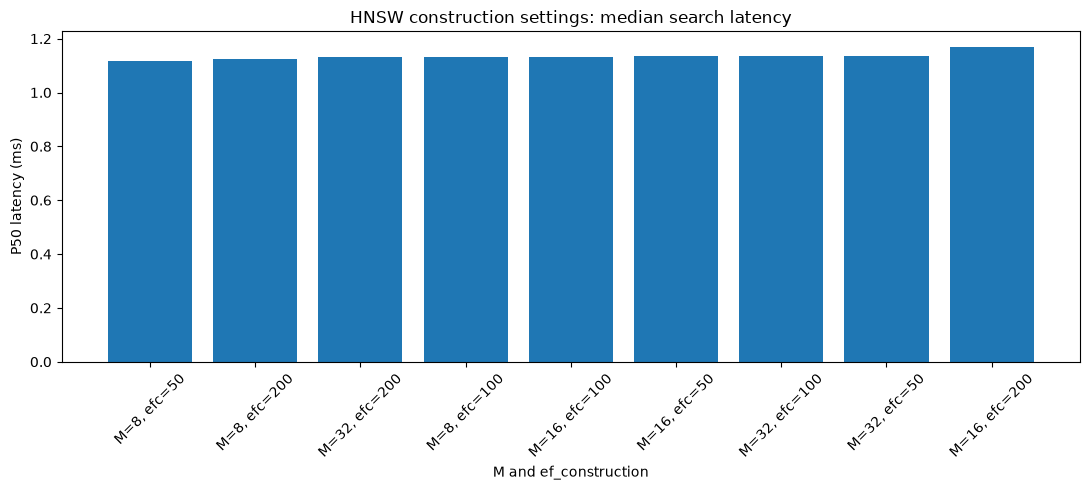

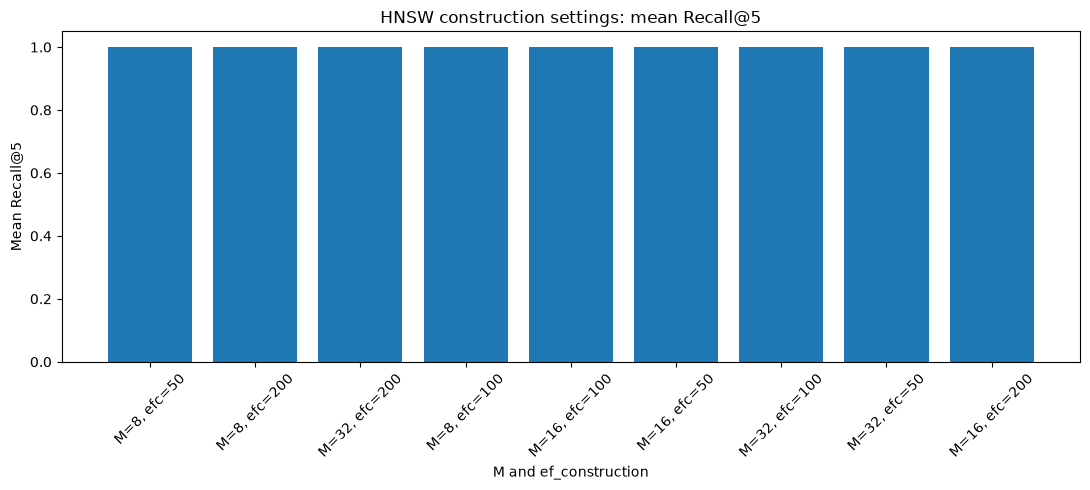

In [4]:
tuning_sorted = tuning.sort_values("p50_ms").copy()
tuning_sorted["configuration"] = tuning_sorted.apply(
    lambda r: f"M={int(r['M'])}, efc={int(r['ef_construction'])}",
    axis=1,
)

display(tuning_sorted[[
    "M", "ef_construction", "ef_search",
    "mean_recall_at_5", "p50_ms", "p95_ms", "p99_ms"
]])

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(tuning_sorted["configuration"], tuning_sorted["p50_ms"])
ax.set_title("HNSW construction settings: median search latency")
ax.set_xlabel("M and ef_construction")
ax.set_ylabel("P50 latency (ms)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(tuning_sorted["configuration"], tuning_sorted["mean_recall_at_5"])
ax.set_title("HNSW construction settings: mean Recall@5")
ax.set_xlabel("M and ef_construction")
ax.set_ylabel("Mean Recall@5")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 3. Final ChromaDB semantic-search benchmark

The final collection is `gigavolt_m4_final`. Query embeddings are generated with `intfloat/e5-small-v2`; the query encoder uses the `query:` prefix, while stored document text used the `passage:` prefix.

**Measurement distinction:** `chroma_final_benchmark.csv` stores one median latency per query and setting. Its latency distribution therefore describes the eight query-level medians, not every individual timed attempt. The benchmark script's terminal output also reports latency percentiles calculated across the repeated search attempts.

,ef_search,mean_recall_at_5,median_of_query_medians_ms,slowest_query_median_ms,query_count
0,10,1.0,2.001359,2.066418,8
1,20,1.0,1.982583,2.061436,8
2,40,1.0,1.978497,2.018147,8
3,80,1.0,1.983061,2.008132,8


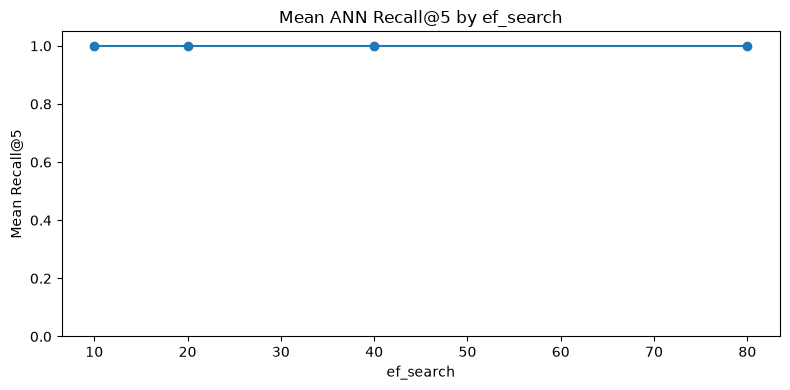

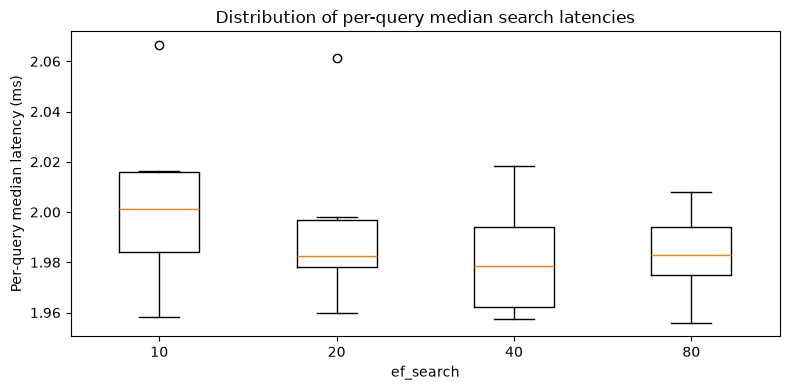

Median database search target: < 20 ms
These latency values exclude model loading and query embedding generation.


In [5]:
benchmark_summary = (
    benchmark.groupby("ef_search")
    .agg(
        mean_recall_at_5=("recall_at_5", "mean"),
        median_of_query_medians_ms=("median_latency_ms", "median"),
        slowest_query_median_ms=("median_latency_ms", "max"),
        query_count=("query", "nunique"),
    )
    .reset_index()
)

display(benchmark_summary)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    benchmark_summary["ef_search"],
    benchmark_summary["mean_recall_at_5"],
    marker="o",
)
ax.set_title("Mean ANN Recall@5 by ef_search")
ax.set_xlabel("ef_search")
ax.set_ylabel("Mean Recall@5")
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
groups = [
    benchmark.loc[
        benchmark["ef_search"] == ef, "median_latency_ms"
    ].to_numpy()
    for ef in sorted(benchmark["ef_search"].unique())
]
labels = sorted(benchmark["ef_search"].unique())

ax.boxplot(groups, tick_labels=[str(x) for x in labels])
ax.set_title("Distribution of per-query median search latencies")
ax.set_xlabel("ef_search")
ax.set_ylabel("Per-query median latency (ms)")
plt.tight_layout()
plt.show()

print("Median database search target: < 20 ms")
print("These latency values exclude model loading and query embedding generation.")

## 4. Source-level retrieval evaluation

The relevance-candidate evaluation used 25 distinct natural-language questions, each with an initially expected source document.

- **Hit@5:** the expected document appeared at least once in the retrieved top five.
- **MRR:** the reciprocal of the rank of the first expected-source match.

These are source-level proxy metrics. They are not equivalent to human-judged relevance.

,query_id,query,expected_source,hit_at_5,expected_source_rank,reciprocal_rank,expected_source_chunks_in_top5,unique_sources_in_top5
0,Q01,What problem and remedy does engineering chang...,GV-ECO-2024-019,1,3,0.333333,1,4
1,Q02,What change was made to address the chiller re...,GV-ECO-2024-031,1,1,1.000000,2,4
2,Q03,What corrective torque requirements are specif...,GV-ECO-2024-044,1,2,0.500000,2,3
3,Q04,What changes are required for the cabinet door...,GV-ECO-2024-052,1,1,1.000000,1,5
4,Q05,What happened during the G-3500 thermal incide...,GV-INC-2024-088,1,1,1.000000,1,5


Distinct questions: 25
Expected-source Hit@5: 1.000
Expected-source MRR: 0.893


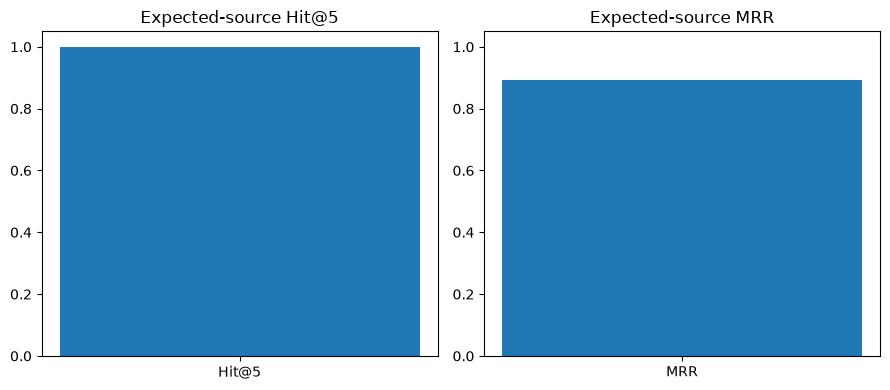

In [6]:
display(source_eval.head())

hit_at_5 = source_eval["hit_at_5"].astype(float).mean()
mrr = source_eval["reciprocal_rank"].astype(float).mean()

print(f"Distinct questions: {source_eval['query_id'].nunique()}")
print(f"Expected-source Hit@5: {hit_at_5:.3f}")
print(f"Expected-source MRR: {mrr:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
axes[0].bar(["Hit@5"], [hit_at_5])
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Expected-source Hit@5")

axes[1].bar(["MRR"], [mrr])
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Expected-source MRR")

plt.tight_layout()
plt.show()

## 5. Human relevance spot-check

Some retrieved candidates were manually reviewed during an interactive spot-check. Only saved labels are included here.

This section reports review coverage and relevance among the judged results. If only part of the candidate set has been reviewed, these values must not be represented as complete Precision@5 or Recall@5 across all queries.

In [7]:
human_file = DATA_DIR / "human_relevance_judgments.csv"

if human_file.exists():
    human = pd.read_csv(human_file, dtype=str).fillna("")
    labels = human["human_relevant"].astype(str).str.strip()
    judged = human[labels.isin(["0", "1"])].copy()
    judged["human_relevant"] = judged["human_relevant"].astype(int)

    total_candidates = len(human)
    judged_count = len(judged)
    positives = int(judged["human_relevant"].sum())

    print(f"Candidate rows in review file: {total_candidates}")
    print(f"Manually judged rows: {judged_count}")
    print(f"Review coverage: {judged_count / total_candidates:.1%}" if total_candidates else "No candidate rows")
    print(f"Judged chunks marked relevant: {positives}")

    if judged_count:
        print(
            "Relevance rate among judged chunks:",
            round(positives / judged_count, 3),
        )
        display(judged[[
            "query_id", "rank", "source_filename",
            "human_relevant", "review_notes"
        ]].head(20))
    else:
        print("No saved binary judgments yet.")
else:
    print("Human judgment CSV not found. Spot-check metrics are unavailable.")

Candidate rows in review file: 125
Manually judged rows: 6
Review coverage: 4.8%
Judged chunks marked relevant: 1
Relevance rate among judged chunks: 0.167


,query_id,rank,source_filename,human_relevant,review_notes
0,Q01,1,GV-ECO-2024-031 Change Order - Chiller Relief ...,0,
1,Q01,2,GV-ECO-2024-052 Change Order Cabinet Door Seal...,0,
2,Q01,3,GV-ECO-2024-019 Engineering Change Order.pdf,1,
3,Q01,4,GV-ECO-2024-044 Change Order Re-torque.pdf,0,
4,Q01,5,GV-ECO-2024-031 Change Order - Chiller Relief ...,0,
5,Q02,1,GV-ECO-2024-031 Change Order - Chiller Relief ...,0,


## 6. Final collection integrity check

This section checks that the saved records still match the validated chunks. If ChromaDB is installed in the notebook's Python environment, it also reads the final collection count and configuration.

In [8]:
print("Validated chunk records:", len(chunks))
print("Unique chunk IDs:", chunks["chunk_id"].nunique())
print("Maximum chunk length:", chunks["token_count"].max())
print("Chunk target met:", bool((chunks["token_count"] <= target).all()))

try:
    import chromadb

    chroma_path = Path(os.getenv("GIGAVOLT_CHROMA_DIR", "../../data/chroma_store")).resolve()
    client = chromadb.PersistentClient(path=str(chroma_path))
    collection = client.get_collection("gigavolt_m4_final")

    print("Final ChromaDB collection:", collection.name)
    print("Final stored record count:", collection.count())
    print("HNSW configuration:", collection.configuration.get("hnsw"))

except Exception as exc:
    print("ChromaDB check not executed in this notebook kernel:", exc)

Validated chunk records: 64
Unique chunk IDs: 64
Maximum chunk length: 300
Chunk target met: True


Final ChromaDB collection: gigavolt_m4_final
Final stored record count: 64
HNSW configuration: {'space': 'cosine', 'ef_construction': 50, 'ef_search': 20, 'max_neighbors': 8, 'resize_factor': 1.2, 'sync_threshold': 100}


## 7. Results and limitations

### Implemented
- PDF text extraction from 25 source documents.
- Configurable document-level chunking with a 300-token target and approximately 50-token overlap.
- 64 validated chunks with source and page-range metadata.
- 384-dimensional E5 embeddings.
- Persistent ChromaDB storage and cosine-distance semantic search.
- Initial HNSW parameter comparisons and sub-20-ms database-search latency.

### Evaluation limitations
- The corpus contains only 64 chunks, so HNSW configurations may return identical nearest neighbors.
- ANN Recall@5 measures agreement with exact vector search, not human relevance.
- The 25 expected-source queries are a source-level proxy test; expected-source labels and retrieved text should be reviewed.
- Human relevance labels are a limited spot-check, not a complete judgment of all 125 candidates.
- Final latency values exclude query embedding generation and model-loading time.

The benchmark results should be interpreted within these limits, and measurements should not be described as a complete evaluation of production-scale retrieval.